# Oil products demand — 02 Research & results: naphtha, Korea and Japan

**Question.** Can a gradient-boosted tree, fed lagged demand and one physical leading indicator, forecast monthly naphtha demand twelve months ahead better than a seasonal naive? And does the indicator, the price of propane against naphtha, help where crackers can switch feed, in **Korea**, and not where they cannot, in **Japan**, where over 95% of ethylene comes from naphtha? Japan is the control.

This notebook reads the point-in-time dataset built in `01_data_naphtha.ipynb` and the walk-forward backtests written by `python -m src.model`. It performs no data operation of its own.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, model, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})

products = ["naphtha_kr", "naphtha_jp"]
TITLES = {"naphtha_kr": "Korea naphtha, kb/d", "naphtha_jp": "Japan naphtha, kb/d"}
STYLE = {"xgboost": dict(color="C1"), "naive": dict(color="C0", ls="--"), "last": dict(color="0.5", ls=":")}

In [2]:
datasets = {p: data.dataset(p) for p in products}            # the panel of notebook 01
bt = sql.query("SELECT * FROM backtest WHERE product LIKE 'naphtha%'")  # one row per product, origin and horizon
marked = model.scored(bt)                                     # target published, no 2020 and no Hormuz

## 1. Key findings

In [3]:
# WAPE in %, averaged over the twelve horizons: the model against its two free benchmarks
headline = pd.DataFrame({p: model.wape(bt[bt["product"] == p]) for p in products}).T
headline.columns = ["xgboost", "seasonal naive", "last value"]
headline["gain on seasonal naive, %"] = 100 * (1 - headline["xgboost"] / headline["seasonal naive"])
headline["gain on best benchmark, %"] = 100 * (1 - headline["xgboost"] / headline[["seasonal naive", "last value"]].min(axis=1))
headline["forecast origins"] = marked.groupby("product")["origin"].nunique()
print(f"walk-forward backtest, monthly origins {marked['origin'].min():%b %Y} to {marked['origin'].max():%b %Y}, WAPE %")
headline

walk-forward backtest, monthly origins Jan 2015 to Jan 2026, WAPE %


,xgboost,seasonal naive,last value,"gain on seasonal naive, %","gain on best benchmark, %",forecast origins
naphtha_kr,6.44,5.82,6.36,-10.58,-10.58,119
naphtha_jp,7.54,7.57,9.75,0.42,0.42,119


In [4]:
# the test that matters: WAPE of the model with the propane/naphtha ratio and without it, by country, and the seed noise
ablation = sql.query(f"SELECT * FROM ablation WHERE product LIKE 'naphtha%' AND since = DATE '{c.BACKTEST_START}'")
seeds = sql.query(f"SELECT * FROM seeds WHERE product LIKE 'naphtha%' AND since = DATE '{c.BACKTEST_START}'")
runs = pd.concat([seeds, ablation[ablation["variant"] == "all drivers"].assign(seed=model.PARAMS["random_state"])])  # four seeds
mean = ablation.groupby(["product", "variant"])["xgboost"].mean().unstack()
mean["ratio helps by, points"] = mean["lags only"] - mean["all drivers"]
mean["seed noise, points"] = runs.groupby(["product", "seed"])["xgboost"].mean().groupby("product").agg(lambda s: s.max() - s.min())
mean.loc[products]

variant,all drivers,lags only,"ratio helps by, points","seed noise, points"
product,,,,
naphtha_kr,6.44,6.42,-0.02,0.09
naphtha_jp,7.54,7.41,-0.13,0.07


- **Korea: no.** Over 119 monthly origins from January 2015 to January 2026, outside 2020 and the closure of Hormuz, the model's WAPE is 6.44% against 5.82% for the seasonal naive: 11% worse. It beats the naive only one month ahead, and over-forecasts at every horizon (bias +1.8% at one month, +5.3% at twelve).
- **Japan: a draw.** 7.54% against 7.57%, a gain of 0.4%, below what a change of random seed moves.
- **The propane price does not do what the test was built to show.** Removing the ratio changes Korea's error by 0.02 points, against a seed noise of 0.09: nothing. In Japan, the control, the model is *better without it*, by 0.13 points on average and by about one point at five and six months, well outside the noise. The expected signature, a gain in Korea and none in Japan, is not there.
- **2026 is out of reach for every forecast.** From March 2026 Korean and Japanese demand fell by up to a third year on year; the three forecasts miss April by 29% to 56%. Nothing in their inputs describes a blockade.

## 2. The forecasting problem

- **Target.** Monthly naphtha demand, JODI's total demand in kb/d, for each country.
- **Origin.** The last day of month *t*. The information set is everything published by then: demand up to *t − 2* (JODI's world database comes out around the 20th of the second month after) and the propane/naphtha ratio as aligned in notebook 01.
- **Horizon.** Months *t+1* to *t+12*, forecast directly: one model per step, each trained on its own target, never a forecast fed back as an input.
- **Benchmarks.** *Seasonal naive*: the same calendar month in the latest year already published at the origin. *Last value*: the newest published print, held flat. Both are free and use the same information set.
- **Model.** `XGBRegressor` on the log deviation from the seasonal naive, `y = log demand(t+step) − log naive`. The forecast is the naive times `exp(prediction)`. If the model learns nothing it predicts zero and returns the naive.
- **Evaluation.** Expanding-window walk-forward: at every month end since January 2015 the twelve models are refitted on what was published by then, and the forecasts are marked later against the published outcome. WAPE (sum of absolute errors over sum of actuals) is the headline; MAE and RMSE in kb/d; bias.
- **Two shocks left out of training and of the headline**: 2020, and the closure of Hormuz from March 2026 (`config.EXCLUDE`). The backtest still forecasts through both; section 6 shows those forecasts apart.

In [5]:
# one past origin, used for the walk-through below: everything published by 31 December 2023
df, lag = datasets["naphtha_kr"], c.DEMAND_LAG["naphtha_kr"]
origin = pd.Timestamp("2023-12-01")
months = pd.date_range(origin + pd.DateOffset(months=1), periods=model.HORIZON, freq="MS", name="target month")
reference = [m - pd.DateOffset(months=model.back(step, lag)) for step, m in enumerate(months, 1)]
print(f"newest demand print at the origin: {origin - pd.DateOffset(months=lag):%B %Y}")
pd.DataFrame({"step": range(1, model.HORIZON + 1), "seasonal naive repeats": reference}, index=months).T

newest demand print at the origin: October 2023


target month,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01
step,1,2,3,4,5,6,7,8,9,10,11,12
seasonal naive repeats,2023-01-01 00:00:00,2023-02-01 00:00:00,2023-03-01 00:00:00,2023-04-01 00:00:00,2023-05-01 00:00:00,2023-06-01 00:00:00,2023-07-01 00:00:00,2023-08-01 00:00:00,2023-09-01 00:00:00,2023-10-01 00:00:00,2022-11-01 00:00:00,2022-12-01 00:00:00


Steps 11 and 12 reach back two years: at the end of December 2023 the figures for November and December 2023 are not out yet. A naive that used them would be looking ahead.

## 3. Demand: level, seasonality, persistence

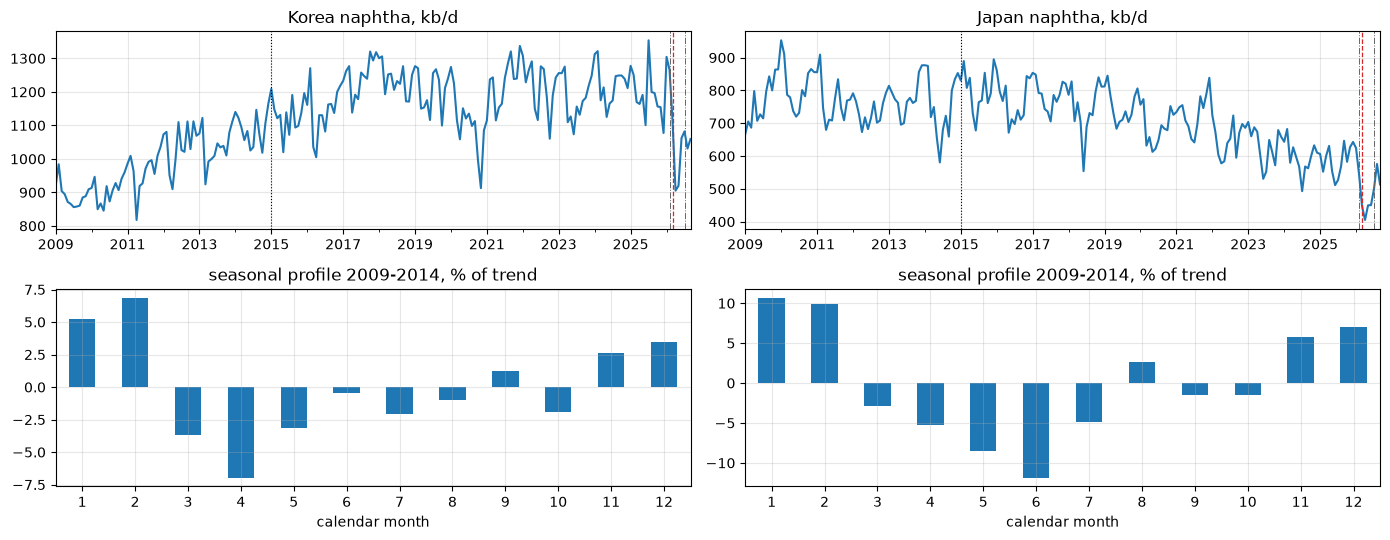

In [6]:
demand = pd.DataFrame({p: datasets[p]["demand"] for p in products}).dropna()
history = demand[demand.index < c.BACKTEST_START]  # only what precedes the backtest informs the design

# seasonal profile: each month against its centred twelve-month average, in %
profile = 100 * (history / history.rolling(12, center=True).mean() - 1)
profile = profile.groupby(profile.index.month).mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 5.5))
for i, p in enumerate(products):
    demand[p].plot(ax=axes[0, i], title=TITLES[p])
    axes[0, i].axvline(pd.Timestamp(c.BACKTEST_START), color="k", lw=.8, ls=":")
    axes[0, i].axvline(pd.Timestamp(c.HORMUZ[0]), color="C3", lw=.9, ls="--")
    for date in c.KOREA_CUTS:
        axes[0, i].axvline(pd.Timestamp(date), color="0.4", lw=.7, ls="-.")
    axes[0, i].set_xlabel("")
    profile[p].plot.bar(ax=axes[1, i], rot=0, title="seasonal profile 2009-2014, % of trend")
    axes[1, i].set_xlabel("calendar month")
plt.tight_layout();

In [7]:
# persistence before the backtest: autocorrelation of the level and of the year-on-year log change
yoy = np.log(history).diff(12)
pd.DataFrame({"level, 1 month": history.apply(lambda s: s.autocorr(1)),
              "level, 12 months": history.apply(lambda s: s.autocorr(12)),
              "year-on-year, 1 month": yoy.apply(lambda s: s.autocorr(1)),
              "year-on-year, 12 months": yoy.apply(lambda s: s.autocorr(12)),
              "seasonal swing, % of trend": profile.max() - profile.min()})

,"level, 1 month","level, 12 months","year-on-year, 1 month","year-on-year, 12 months","seasonal swing, % of trend"
naphtha_kr,0.78,0.78,0.22,-0.31,13.81
naphtha_jp,0.65,0.41,0.64,-0.25,22.50


In [8]:
# the switch to propane, in the context series: LPG demand against naphtha demand, kb/d a year
lpg = sql.query("SELECT product, period_end, value FROM predictors WHERE variable = 'lpg'").pivot(index="period_end", columns="product", values="value")
lpg.index = pd.to_datetime(lpg.index).to_period("M").to_timestamp()
yearly = pd.concat({"naphtha": demand.resample("YE").mean(), "lpg": lpg.resample("YE").mean()}, axis=1, sort=True)
yearly.index = yearly.index.year
yearly.loc[2009:].T.round(0)

2009   2010   2011     2012     2013     2014     2015     2016     2017     2018     2019     2020     2021     2022     2023     2024     2025     2026
naphtha naphtha_kr 891.00 905.00 965.00 1,041.00 1,037.00 1,089.00 1,130.00 1,141.00 1,246.00 1,237.00 1,204.00 1,107.00 1,224.00 1,215.00 1,184.00 1,224.00 1,191.00 1,083.00
        naphtha_jp 764.00 815.00 768.00   734.00   779.00   750.00   801.00   765.00   788.00   744.00   752.00   686.00   732.00   653.00   632.00   597.00   588.00   501.00
lpg     naphtha_jp 484.00 470.00 482.00   518.00   491.00   475.00   423.00   425.00   407.00   384.00   352.00   324.00   340.00   364.00   386.00   377.00   374.00   365.00
        naphtha_kr 292.00 289.00 275.00   262.00   254.00   247.00   250.00   302.00   290.00   300.00   339.00   335.00   332.00   362.00   339.00   368.00   353.00   324.00

- **Two different markets.** Korean demand rose by 40% from 2009 to 2017 and has been flat since, around 1,200 kb/d; Japanese demand has drifted down from about 800 kb/d to 590 in 2025, and 500 so far in 2026. A model trained on Korea's growth years learns growth that stopped.
- **Japan is the more seasonal**: a swing of 22% of trend against 14% for Korea, the spring turnarounds of its crackers. That is what the seasonal naive captures and why holding the last value flat does badly there.
- **Little momentum to exploit in Korea**: the year-on-year change has an autocorrelation of 0.22 from one month to the next, against 0.64 in Japan. Lagged growth, the core of the model, says little about Korea's next month.
- **The switch to propane is real, and structural.** Korea's LPG demand rose from about 250 kb/d in 2013-2015 to 330-370 since 2019, while its naphtha stopped growing; Japan's LPG fell. That is a capacity story, crackers built or converted to run propane, not a monthly response to price.

## 4. Features

Everything enters in year-on-year terms, so the model sees growth rather than levels: the last twelve published demand prints (`yoy_lag`), and the propane/naphtha ratio as readable at the origin against its value a year earlier. The ratio also enters as a **level**: a cracker switches feed when propane is cheap enough against naphtha, some 50 USD/t under it in practice, a threshold a year-on-year change cannot see.

In [9]:
X, y = model.features(df, lag, step=12)
X.loc[origin].to_frame(f"origin {origin:%b %Y}").T  # one row: the information set at the origin

,yoy_lag2,yoy_lag3,yoy_lag4,yoy_lag5,yoy_lag6,yoy_lag7,yoy_lag8,yoy_lag9,yoy_lag10,yoy_lag11,yoy_lag12,yoy_lag13,propane_naphtha,propane_naphtha_level
origin Dec 2023,0.11,-0.01,-0.11,-0.10,-0.04,-0.02,-0.15,0.01,0.02,-0.04,-0.07,-0.04,-0.02,0.90


In [10]:
# the target at this origin by hand: log of December 2024 over December 2022, the naive's reference
target = origin + pd.DateOffset(months=12)
by_hand = np.log(df.loc[target, "demand"] / df.loc[target - pd.DateOffset(months=model.back(12, lag)), "demand"])
assert abs(by_hand - y.loc[origin]) < 1e-12
by_hand

np.float64(-0.02569690063273465)

In [11]:
# what the driver on that row describes, and when it was published: read from the stored panel
info = sql.query(f"""
    SELECT variable, period_end, available_at, month_end AS origin
    FROM panel WHERE product = 'naphtha_kr' AND month = DATE '{origin:%Y-%m-%d}' ORDER BY variable
""")
assert (info["available_at"] <= info["origin"]).all()
info

,variable,period_end,available_at,origin
0,propane_naphtha,2023-11-30,2023-12-31,2023-12-31


## 5. Training and tuning without look-ahead

**Training rows.** A row can be used at an origin only if its *target* had been published by then. For the twelve-month model that removes the last fourteen months before the origin, not twelve. Rows whose origin, target or naive reference falls in 2020 or after the closure of Hormuz are left out of training: the model is not asked to learn a lockdown or a blockade.

In [12]:
rows = model.trainable(y, step=12, product="naphtha_kr", origin=origin)
last = X.index[rows].max()
assert last + pd.DateOffset(months=12 + lag) <= origin  # its target was published by the origin
pd.DataFrame({"training rows": [rows.sum()], "first origin": [X.index[rows].min()], "last origin": [last],
              "its target month": [last + pd.DateOffset(months=12)],
              "target published by the end of": [last + pd.DateOffset(months=12 + lag)]})

,training rows,first origin,last origin,its target month,target published by the end of
0,118,2010-01-01,2022-10-01,2023-10-01,2023-12-01


In [13]:
# one model per horizon, each with its own training rows; and at the first backtest origin, January 2015
first = pd.Timestamp(c.BACKTEST_START)
pd.DataFrame({when: {step: model.trainable(model.features(df, lag, step)[1], step, "naphtha_kr", at).sum() for step in range(1, model.HORIZON + 1)}
              for when, at in (("origin Dec 2023", origin), ("first origin, Jan 2015", first))}).T

,1,2,3,4,5,6,7,8,9,10,11,12
origin Dec 2023,142,142,142,142,142,142,142,142,142,142,119,118
"first origin, Jan 2015",59,59,59,59,59,59,59,59,59,59,47,47


**Tuning.** Eight parameter sets, chosen once per product at the first backtest origin by expanding-window cross-validation on the data published by then. The backtest years play no part in the choice. The grid is small on purpose: JODI's naphtha starts in 2009, so at the first origin the twelve-month model has fewer than fifty rows.

In [14]:
fit_rows = model.trainable(y, 12, "naphtha_kr", first)
cv = pd.DataFrame(model.GRID)
cv["cv rmse, %"] = [100 * np.sqrt(model.cv_score(X[fit_rows], y[fit_rows], 12, lag, params)) for params in model.GRID]
cv.sort_values("cv rmse, %")

,learning_rate,max_depth,n_estimators,"cv rmse, %"
6,0.10,5,200,11.17
7,0.10,5,600,11.17
2,0.03,5,200,11.18
5,0.10,3,600,11.20
4,0.10,3,200,11.21
0,0.03,3,200,11.22
3,0.03,5,600,11.23
1,0.03,3,600,11.26


In [15]:
params = sql.query("SELECT * FROM params WHERE product LIKE 'naphtha%'").set_index("product")
assert model.tuned("naphtha_kr") == model.tune(df, "naphtha_kr", first)
params

,learning_rate,max_depth,n_estimators
product,,,
naphtha_kr,0.10,5,200
naphtha_jp,0.03,5,200


The cross-validated errors of the eight sets lie between 11.2% and 11.3%: the choice barely matters, which is what a grid this small on fewer than 60 rows should show. Korea's search picked a learning rate of 0.10 and depth 5, Japan's 0.03 and depth 5, both with 200 trees. At the first origin the twelve-month model has 47 rows, the others 59: every naphtha result rests on a small sample.

**The direct test for look-ahead.** Delete from the dataset everything that was not published at the origin, the demand prints of the last two months and every later row, and forecast again. If any step of the pipeline read the future, the forecast would change.

In [16]:
path = model.forecast(df, "naphtha_kr", origin, model.tuned("naphtha_kr"))
known = df.loc[:origin].copy()
known.loc[known.index > origin - pd.DateOffset(months=lag), "demand"] = np.nan  # not published yet at the origin
assert (model.forecast(known, "naphtha_kr", origin, model.tuned("naphtha_kr")) == path).all()

## 6. Walk-forward backtest

The same procedure from every month end since January 2015, for both countries, stored by `python -m src.model`.

In [17]:
# integrity of the stored backtest: every target is after its origin, and every naive reference had been published by the origin
def months_between(start, end):
    return (end.dt.year - start.dt.year) * 12 + end.dt.month - start.dt.month

assert (months_between(bt["origin"], bt["month"]) == bt["step"]).all()
assert (months_between(bt["reference"], bt["origin"]) >= bt["product"].map(c.DEMAND_LAG)).all()
bt.groupby("product").agg(origins=("origin", "nunique"), first_origin=("origin", "min"), last_origin=("origin", "max"),
                          forecasts=("xgboost", "count"), marked=("actual", "count"))

,origins,first_origin,last_origin,forecasts,marked
product,,,,,
naphtha_jp,141,2015-01-01,2026-09-01,1692,1614
naphtha_kr,141,2015-01-01,2026-09-01,1692,1614


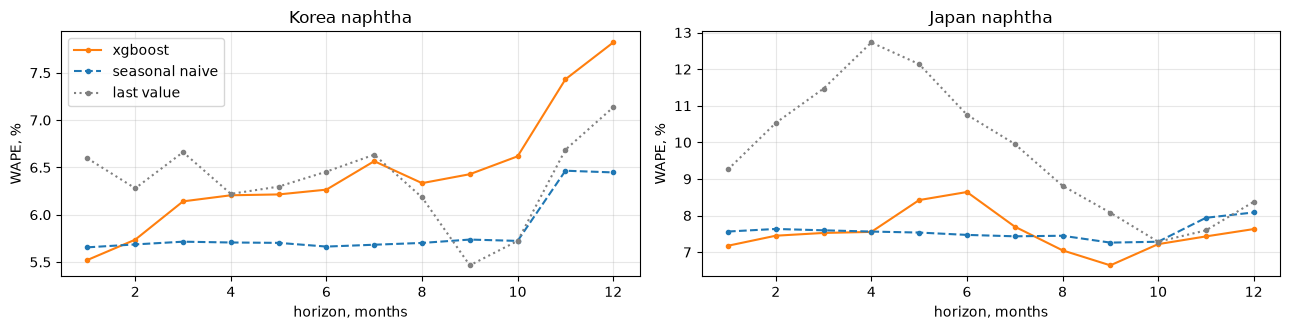

In [18]:
# error by horizon
by_step = {p: model.score(marked[marked["product"] == p]) for p in products}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, p in zip(axes, products):
    for name in model.FORECASTS:
        by_step[p]["wape"][name].plot(ax=ax, marker="o", ms=3, label={"xgboost": "xgboost", "naive": "seasonal naive", "last": "last value"}[name], **STYLE[name])
    ax.set_title(TITLES[p].split(",")[0]); ax.set_xlabel("horizon, months"); ax.set_ylabel("WAPE, %")
axes[0].legend()
plt.tight_layout();

In [19]:
# every metric, averaged over the twelve horizons. MAE and RMSE in kb/d, WAPE and bias in %
pd.concat({p: by_step[p].mean().unstack(0) for p in products})

mae  rmse  wape  bias
naphtha_kr xgboost 77.48 95.48  6.44  3.30
           naive   70.06 87.23  5.82 -0.91
           last    76.52 93.86  6.36 -0.25
naphtha_jp xgboost 52.33 68.02  7.54  3.24
           naive   52.55 67.68  7.57  3.17
           last    67.70 83.88  9.75  2.37

- **Korea: the naive wins from two months on.** The model is level with it at one month (5.5% against 5.7%) and falls behind steadily to 7.8% against 6.5% at twelve. Its bias grows with the horizon, from +1.8% to +5.3%: it keeps forecasting the growth of its early training years.
- **Japan: a small gain at one to three months, a clear loss at five and six.** 7.2% against 7.6% one month ahead; 8.4% and 8.6% against 7.5% at five and six months, the horizons where the propane ratio does damage (section 7). From eight months on the model edges ahead again.
- **The last value is the worst benchmark in Japan** (9.8%) because of the seasonality, and close to the naive in Korea, which has less of it.

In [20]:
# by target year, WAPE %. This table keeps 2020, 2026 and the months that reference them, which the headline leaves out
everything = model.scored(bt, shocks=True)
everything = everything.assign(year=everything["month"].dt.year)
by_year = pd.concat({p: model.score(everything[everything["product"] == p], "year")["wape"][["xgboost", "naive", "last"]] for p in products}, axis=1)
by_year

naphtha_kr             naphtha_jp            
        xgboost naive  last    xgboost naive  last
year                                              
2015       3.88  4.37  5.27       9.27  9.20  9.43
2016       5.71  5.50  6.90       8.08  7.05  9.97
2017       5.71  8.68  7.23       4.57  4.48  8.03
2018       6.23  5.98  4.87       6.14  6.29 10.35
2019       8.51  4.26  5.54       5.98  5.51  9.13
2020      14.75  9.31  9.61       7.45  9.61 11.27
2021      10.47 10.65  9.89       6.07  7.21  8.89
2022       6.93  6.98  7.20      11.86 12.03 13.46
2023       5.73  5.49  7.09      10.41 10.12 10.42
2024       5.44  5.18  6.13       7.90  8.79  9.85
2025       8.60  6.11  6.40       6.19  6.99  8.58
2026      16.16 12.76 13.98      15.20 16.69 20.20

In [21]:
# 2026 apart: the forecasts the headline leaves out because their target, origin or reference falls after the closure of Hormuz
hormuz = everything[everything["month"] >= c.HORMUZ[0]]
pd.concat({p: model.score(hormuz[hormuz["product"] == p], "month")["wape"][["xgboost", "naive", "last"]] for p in products}, axis=1)

naphtha_kr             naphtha_jp            
              xgboost naive  last    xgboost naive  last
month                                                   
2026-03-01      11.84  5.13  7.70      28.66 33.36 31.30
2026-04-01      31.78 29.49 31.82      53.44 55.56 45.38
2026-05-01      31.11 28.29 29.85      23.63 24.85 30.85
2026-06-01       9.32  4.65 12.01      13.54 15.61 27.90
2026-07-01      22.67 22.37 10.77       3.03  4.68 16.17
2026-08-01      21.55 17.12 14.95       4.49  1.21 11.87
2026-09-01      17.78 13.77 12.46      12.96 23.15 15.52

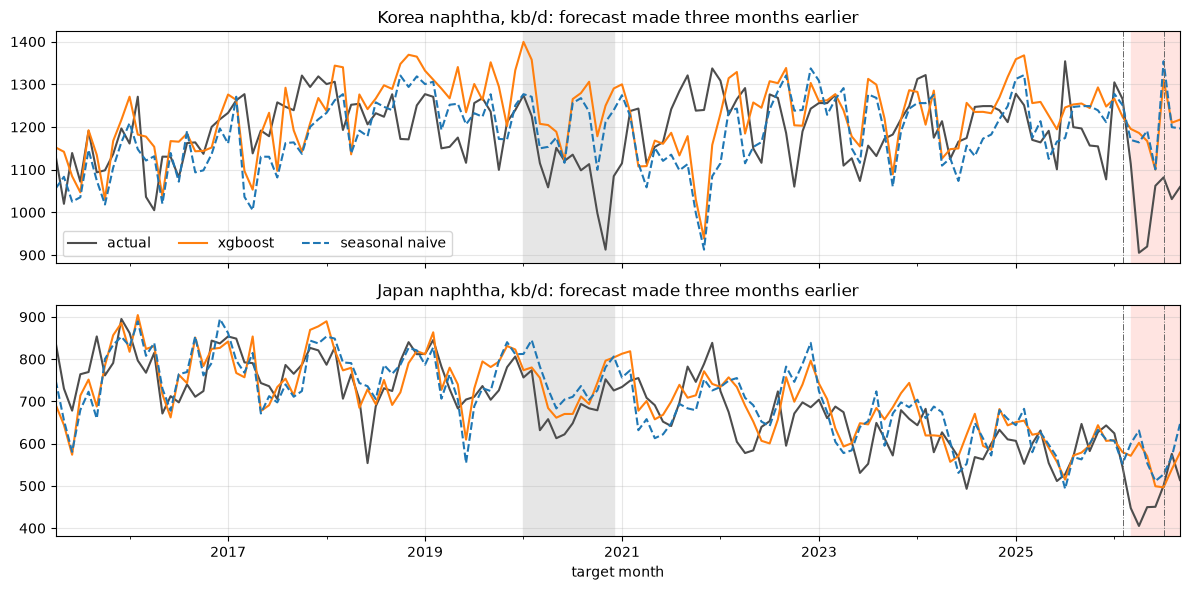

In [22]:
# actual against forecast, three months ahead, with the two shocks shaded
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, p in zip(axes, products):
    three = everything[(everything["product"] == p) & (everything["step"] == 3)].set_index("month")
    three["actual"].plot(ax=ax, color="0.3", label="actual")
    three["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
    three["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
    ax.axvspan(pd.Timestamp(c.COVID[0]), pd.Timestamp(c.COVID[1]), color="0.9")
    ax.axvspan(pd.Timestamp(c.HORMUZ[0]), three.index.max(), color="mistyrose")
    for date in c.KOREA_CUTS:
        ax.axvline(pd.Timestamp(date), color="0.4", lw=.7, ls="-.")
    ax.set_title(f"{TITLES[p]}: forecast made three months earlier"); ax.set_xlabel("target month")
axes[0].legend(ncol=3)
plt.tight_layout();

- **No year in which the model is reliably better.** In Korea it wins clearly only in 2017 (5.7% against 8.7%) and loses heavily in 2019 (8.5% against 4.3%), 2020 and 2025 (8.6% against 6.1%). In Japan it stays within about a point of the naive every year, ahead in 2020-2021 and 2024-2025, behind in 2016 and 2019.
- **The 2026 months, shown apart.** March 2026 is already off in Japan (all three forecasts miss by 29% to 33%), April is the worst month in both countries, and Korea's errors stay above 10% for all three forecasts from July to September. In Japan the model and the naive fall back below 5% in July and August, as Gulf cargoes returned to half of its imports.
- **Why the shock starts in March, not April.** The customs show the Gulf's share of Japan's naphtha imports falling only in April (73% in March, 29% in April), because the March cargoes were already at sea. Demand fell first: Japan's March 2026 was 25% below March 2025, as crackers cut runs to stretch stocks. Starting the exclusion in April would have trained and scored the model on a month already shaped by the closure. The date was set after seeing these figures, which is said here rather than hidden; the dashed line on the charts marks it, the dash-dot lines the approval of the Daesan (February) and Yeosu (July) restructurings.

## 7. Does the propane price help? Korea against Japan

The honest version of feature importance is out-of-sample: rerun the backtest without the ratio and see whether the error moves, horizon by horizon. It is read against a yardstick: the same model with three other random seeds, which shows how much the score moves for no reason at all. Korean crackers can run propane in place of part of their naphtha; Japanese crackers almost cannot. If the ratio carries information about demand, it should show in Korea and not in Japan.

ratio helps by            seed noise           
product     naphtha_jp naphtha_kr naphtha_jp naphtha_kr
step                                                   
1                -0.04      -0.07       0.14       0.17
2                -0.09       0.15       0.22       0.14
3                 0.16      -0.10       0.20       0.52
4                -0.15       0.07       0.14       0.15
5                -0.94      -0.08       0.26       0.19
6                -1.18      -0.17       0.06       0.21
7                -0.33      -0.05       0.32       0.43
8                 0.41       0.06       0.29       0.08
9                 0.33       0.08       0.27       0.31
10               -0.16      -0.17       0.34       0.29
11                0.17       0.03       0.13       0.27
12                0.29      -0.03       0.16       0.24

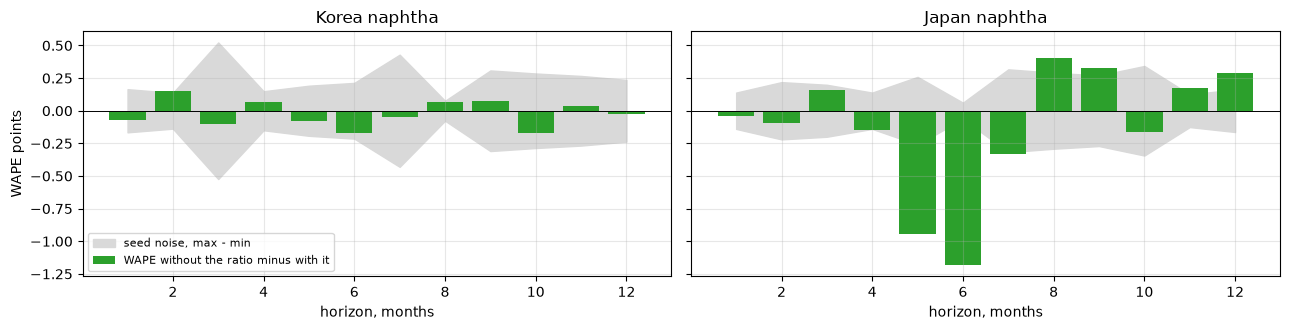

In [23]:
steps = ablation.pivot_table(index=["product", "step"], columns="variant", values="xgboost")
band = runs.groupby(["product", "step"])["xgboost"].agg(lambda s: s.max() - s.min()).rename("seed noise")
gain = (steps["lags only"] - steps["all drivers"]).rename("ratio helps by").to_frame().join(band)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, p in zip(axes, products):
    g = gain.loc[p]
    ax.bar(g.index, g["ratio helps by"], color="C2", label="WAPE without the ratio minus with it")
    ax.fill_between(g.index, -g["seed noise"], g["seed noise"], color="0.85", label="seed noise, max - min", zorder=0)
    ax.axhline(0, color="k", lw=.7); ax.set_title(TITLES[p].split(",")[0]); ax.set_xlabel("horizon, months")
axes[0].set_ylabel("WAPE points"); axes[0].legend(fontsize=8)
plt.tight_layout();
gain.unstack(0).round(2)

- **Korea: the ratio carries nothing.** At no horizon does removing it move the error by more than the seed noise, give or take 0.01 point at two months; the average change is 0.02 points.
- **Japan: the ratio hurts.** At five and six months the model is 0.9 and 1.2 points better without it, against a seed noise of 0.3 and 0.1. With fewer than 60 training rows, a feature without information is a feature the trees can overfit.
- **What this does and does not say.** It says the CIF ratio, as readable at each month end, does not improve a twelve-month forecast of total demand in this sample. It does not say Korean crackers ignore the price of propane: the switch shows in annual LPG demand (section 3). A unit value that averages term and spot cargoes a month late, used for a total that includes non-cracker naphtha, is a blunt instrument for a decision taken cargo by cargo.

## 8. Current forecast

The same models fitted at the latest origin, with the parameters the backtest chose. The latest origins fall after the closure of Hormuz, which the model was not trained on: the forecast is shown, and section 6 says how far to trust it.

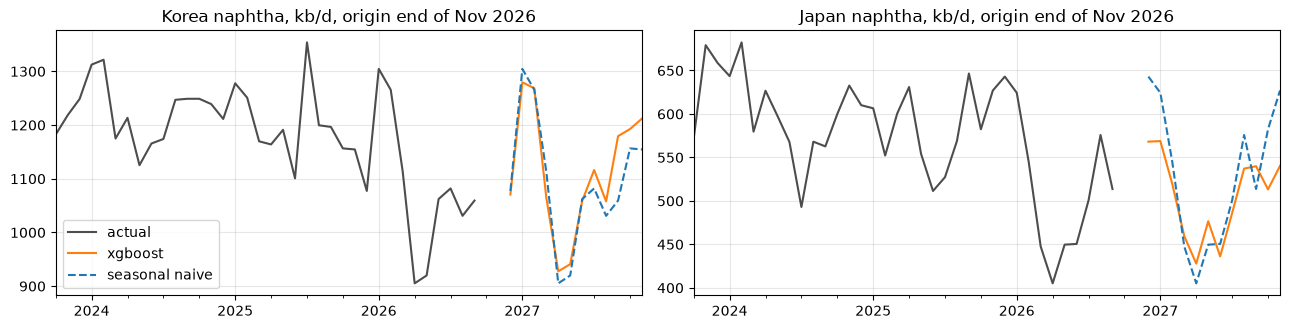

In [24]:
latest = {}
for p in products:
    last_origin = datasets[p].index[-1]
    latest[p] = pd.DataFrame({"xgboost": model.forecast(datasets[p], p, last_origin, model.tuned(p)),
                              "naive": model.seasonal_naive(datasets[p], c.DEMAND_LAG[p], last_origin)})
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, p in zip(axes, products):
    datasets[p]["demand"].dropna().iloc[-36:].plot(ax=ax, color="0.3", label="actual")
    latest[p]["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
    latest[p]["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
    ax.set_title(f"{TITLES[p]}, origin end of {datasets[p].index[-1]:%b %Y}"); ax.set_xlabel("")
axes[0].legend()
plt.tight_layout();

In [25]:
# the forecast as a deviation from the seasonal naive, in %
pd.DataFrame({p: 100 * (latest[p]["xgboost"] / latest[p]["naive"] - 1) for p in products}).T

,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-09-01,2027-10-01,2027-11-01
naphtha_kr,-0.63,-1.91,0.23,-4.33,2.48,2.28,-0.33,3.17,2.62,11.32,3.12,4.98
naphtha_jp,-11.64,-8.89,-4.63,2.69,5.59,5.99,-3.18,-2.93,-6.71,5.10,-11.87,-13.83


Korea's forecast stays within 5% of the seasonal naive except for one step (+11% in September 2027), the kind of isolated jump the backtest gives no reason to trust. Japan's sits 9% to 14% under the naive in the first two and the last two months: the model reads the 2026 collapse in its lagged growth, a pattern it was never trained on, and extends it.

Neither line is a forecast to act on. The naive repeats months from before the closure; the model extrapolates the closure itself. Where Korean and Japanese naphtha demand goes in 2027 depends on when Gulf cargoes return and how much cracker capacity closes, two supply questions outside this dataset.

## 9. Limitations

- **Not a vintage backtest.** Publication delays are respected, revisions are not: past customs years are the definitive figures, not the preliminary ones a forecaster saw (notebook 01, section 5).
- **Small sample.** JODI's naphtha starts in 2009: 47 to 59 training rows at the first origin, 119 marked origins with overlapping twelve-month targets. Neighbouring errors are correlated, the differences are not tested formally and should be read as indications.
- **The feature.** A Japanese CIF unit value: term and spot cargoes mixed, priced weeks before they land, and used for Korea on the ground that both buy on the same North Asian market. A daily spread between propane and naphtha assessments would test the switch more sharply; it is not free.
- **The unit.** kb/d is JODI's conversion of kilotonnes at a fixed 8.5 barrels a tonne.
- **Shocks.** 2020 and the months from March 2026 are excluded from training and from the headline by explicit rule; the March start was chosen after seeing the 2026 data (section 6). The Korean cracker restructurings approved in February and July 2026 lower demand structurally; the model knows nothing of them, and their effect is mixed with the closure of Hormuz.
- **One benchmark family.** Seasonal naive and last value. An ETS or SARIMA model would be a fairer statistical rival.
- **Predictive, not causal.** The ablation says what improved forecasts in this sample, not what moves crackers.

## 10. Conclusion

A gradient-boosted tree fed lagged demand and the price of propane against naphtha does **not** forecast monthly naphtha demand twelve months ahead better than a seasonal naive. In Korea it is worse at every horizon beyond one month; in Japan it is a draw. The test designed to isolate the feedstock switch, Korea against a Japanese control, finds no information in the ratio for Korea and a cost in Japan.

For a desk, the answer is in the context series rather than the model: Korea's move to propane is a structural shift in its cracker fleet, visible in annual LPG demand, and 2026 is a supply shock. A forecast for 2027 starts from Gulf cargo arrivals and cracker closures, not from last year's shape.

Next steps that could change the answer: a daily propane-naphtha spread in place of customs unit values, cracker-level run rates where they are published, and a statistical benchmark as a second rival.